In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
train_data = pd.read_csv("fashion-mnist_train.csv")
test_data = pd.read_csv("fashion-mnist_test.csv")

In [ ]:
y_train = train_data.iloc[:, 0].values
x_train = train_data.iloc[:, 1:].values

y_test = test_data.iloc[:, 0].values
x_test = test_data.iloc[:, 1:].values

In [ ]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [ ]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (16565, 28, 28, 1)
Testing images: (10000, 28, 28, 1)


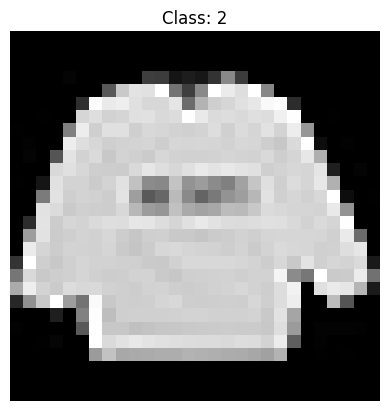

In [ ]:
plt.imshow(x_train[0].reshape(28, 28), cmap='gray')
plt.title("Class: " + str(y_train[0]))
plt.axis('off')
plt.show()

In [ ]:
# Create CNN model
model = keras.Sequential([

    # Convolution layer
    layers.Conv2D(32, (3, 3), activation='relu',
                  input_shape=(28, 28, 1)),

    # Max pooling
    layers.MaxPooling2D((2, 2)),

    # Second convolution layer
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Second max pooling
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Output layer
    layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
466/466 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.7777 - loss: 0.6262 - val_accuracy: 0.8220 - val_loss: nan
Epoch 2/5
466/466 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.8513 - loss: 0.4050 - val_accuracy: 0.8346 - val_loss: nan
Epoch 3/5
466/466 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.8728 - loss: 0.3522 - val_accuracy: 0.8636 - val_loss: nan
Epoch 4/5
466/466 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.8865 - loss: 0.3126 - val_accuracy: 0.8751 - val_loss: nan
Epoch 5/5
466/466 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.8954 - loss: 0.2804 - val_accuracy: 0.8721 - val_loss: nan


In [ ]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8814 - loss: 0.3315
Test Loss: 0.33153414726257324
Test Accuracy: 0.8813999891281128


In [ ]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

In [ ]:
prediction = model.predict(x_test[0:1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step


In [ ]:
predicted_class = prediction.argmax()
actual_class = y_test[0]

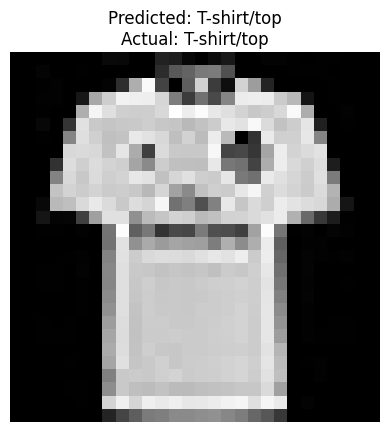

In [ ]:
plt.imshow(x_test[0].reshape(28, 28), cmap='gray')
plt.title(
    "Predicted: " + class_names[predicted_class] +
    "\nActual: " + class_names[actual_class]
)

plt.axis('off')
plt.show()

In [ ]:
print("Predicted Class:", class_names[predicted_class])
print("Actual Class:", class_names[actual_class])

Predicted Class: T-shirt/top
Actual Class: T-shirt/top
